## 1. Imports and Config

In [18]:
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score,
    ConfusionMatrixDisplay
)
from sklearn.ensemble import RandomForestClassifier

artifacts = joblib.load('eda_artifacts.pkl')
df = artifacts['df']
num_features = artifacts['num_features']
iso_anomaly = artifacts['iso_anomaly']

print('Data loaded from EDA.')

Data loaded from EDA.


---
## 2. Data Preparation

In [19]:
df_model = df[num_features + ['Type', 'Target']].copy()
df_model = pd.get_dummies(df_model, columns=['Type'], drop_first=False)

feature_cols = [c for c in df_model.columns if c != 'Target']
X_all = df_model[feature_cols].values
y_all = df_model['Target'].values

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.20, random_state=17, stratify=y_all
)

print(f'Train: {X_train.shape[0]} samples\nTest: {X_test.shape[0]} samples')
print(f'Train failures: {y_train.sum()} ({y_train.mean()*100:.1f}%)')
print(f'Test  failures: {y_test.sum()}  ({y_test.mean()*100:.1f}%)')
print(f'\nFeatures: {len(feature_cols)}\n{feature_cols}')

Train: 8000 samples
Test: 2000 samples
Train failures: 271 (3.4%)
Test  failures: 68  (3.4%)

Features: 8
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_H', 'Type_L', 'Type_M']


---
## 3. Training and Basic Evaluation

In [58]:
rf = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=18,
    n_jobs=-1
)
rf.fit(X_train, y_train)

y_pred  = rf.predict(X_test)
y_proba = rf.predict_proba(X_test)[:, 1]

print('- Classification Report -')
print(classification_report(y_test, y_pred, target_names=['No Failure', 'Failure']))

roc_auc = roc_auc_score(y_test, y_proba)
avg_prec = average_precision_score(y_test, y_proba)
print(f'ROC-AUC: {roc_auc:.4f}')
print(f'Average Precision: {avg_prec:.4f}')

- Classification Report -
              precision    recall  f1-score   support

  No Failure       0.98      1.00      0.99      1932
     Failure       1.00      0.34      0.51        68

    accuracy                           0.98      2000
   macro avg       0.99      0.67      0.75      2000
weighted avg       0.98      0.98      0.97      2000

ROC-AUC: 0.9852
Average Precision: 0.8498


---
## 4. Confusion Matrix

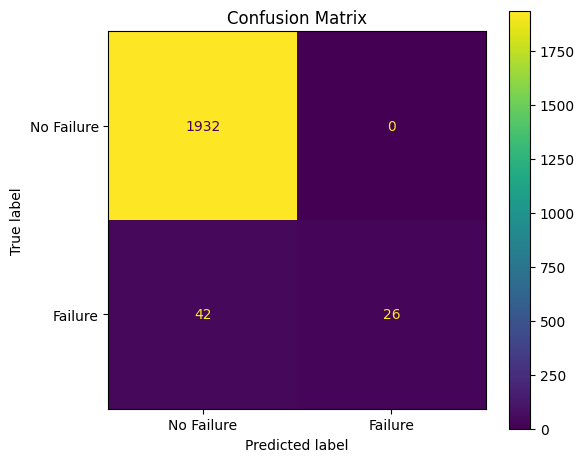


False Alarm Rate: 0.000
Miss Rate: 0.618


In [32]:
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=['No Failure', 'Failure'])
disp.plot(ax=ax)
ax.set_title('Confusion Matrix')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'\nFalse Alarm Rate: {fp/(fp+tn):.3f}')
print(f'Miss Rate: {fn/(fn+tp):.3f}')

---
## 5. ROC Curve and Precision-Recall Curve

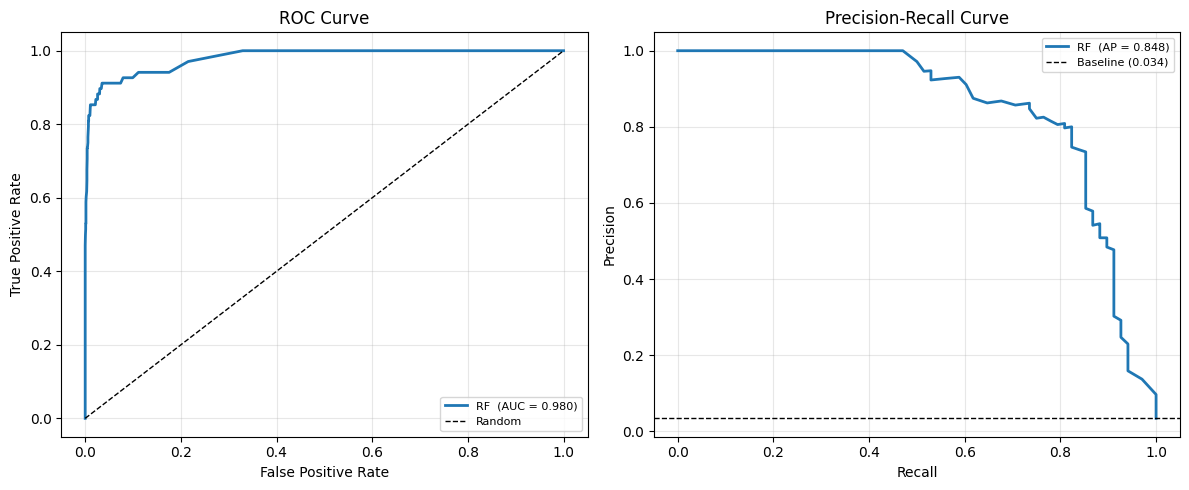

In [34]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
prec, rec, _ = precision_recall_curve(y_test, y_proba)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC
ax = axes[0]
ax.plot(fpr, tpr, lw=2, label=f'RF  (AUC = {roc_auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Precision-Recall
ax = axes[1]
ax.plot(rec, prec, lw=2, label=f'RF  (AP = {avg_prec:.3f})')
baseline = y_test.mean()
ax.axhline(baseline, color='k', linestyle='--', lw=1, label=f'Baseline ({baseline:.3f})')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 6. Feature Importance

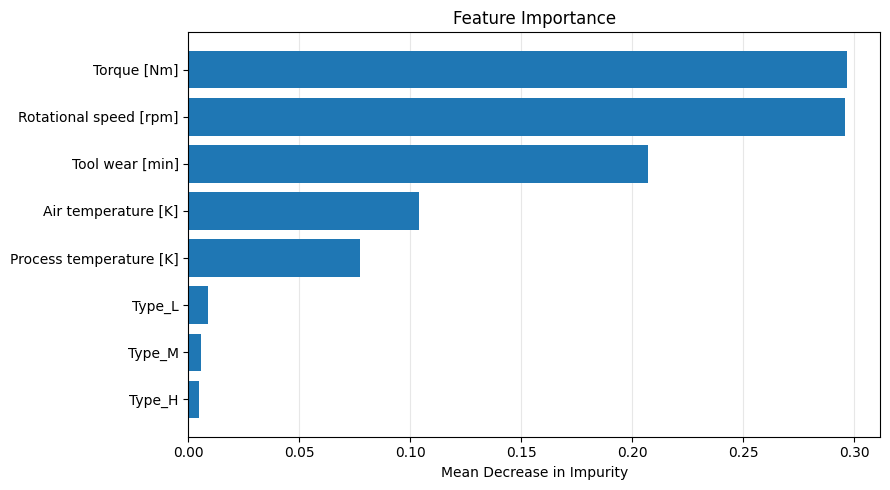

Sorted Feature importances:
 Torque [Nm]:  0.2968
 Rotational speed [rpm]:  0.2959
 Tool wear [min]:  0.2072
 Air temperature [K]:  0.1037
 Process temperature [K]:  0.0773
 Type_L:  0.0086
 Type_M:  0.0057
 Type_H:  0.0048


In [54]:
importances = rf.feature_importances_
idx = np.argsort(importances)[::-1]
sorted_feats = [feature_cols[i] for i in idx]
sorted_imps = importances[idx]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(sorted_feats[::-1], sorted_imps[::-1])
ax.set_title('Feature Importance')
ax.set_xlabel('Mean Decrease in Impurity')
ax.xaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

print('Sorted Feature importances:')
for f, imp in zip(sorted_feats, sorted_imps):
    print(f' {f:}:  {imp:.4f}')

---
## 7. Cross-validation (Stratified 5-Fold)

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=17)

cv_results = cross_validate(
    rf, X_all, y_all, cv=cv,
    scoring=['roc_auc', 'average_precision', 'f1', 'recall', 'precision'],
    return_train_score=False
)

metrics = {
    'ROC-AUC': cv_results['test_roc_auc'],
    'Avg Precision': cv_results['test_average_precision'],
    'F1 (Failure)': cv_results['test_f1'],
    'Recall (Failure)': cv_results['test_recall'],
    'Precision (Failure)': cv_results['test_precision'],
}

print('- Cross-Validation Results (5-Fold) -')
print(f'{"Metric":<30} {"Mean":>8} {"Std":>8} {"Min":>8} {"Max":>8}')
print('-' * 70)
for name, vals in metrics.items():
    print(f'{name:<35} {vals.mean():>8.4f} {vals.std():>8.4f} {vals.min():>8.4f} {vals.max():>8.4f}')

- Cross-Validation Results (5-Fold) -
Metric                             Mean      Std      Min      Max
----------------------------------------------------------------------
ROC-AUC                     0.9664   0.0118   0.9549   0.9831
Avg Precision               0.7563   0.0538   0.6565   0.8138
F1 (Failure)                0.5678   0.0619   0.5000   0.6729
Recall (Failure)            0.4158   0.0659   0.3382   0.5294
Precision (Failure)         0.9111   0.0399   0.8438   0.9583
